# 🎬 Movie Recommendation System
Content-based + hybrid recommender built on `Movie_Recommendation_System.xlsx` (100 movies, 200 users, 400 ratings).

**Workflow:** 1 Imports → 2 Load → 3 Understand → 4 Clean → 5 Select features → 6 Preprocess → 7 Vectorize → 8 Feature matrix → 9 Cosine similarity → 10 Recommend function → 11 Test → 12 Save → *(13–15 Streamlit app, run locally, deploy: see `app.py` and `README.md`)*

## 1. Import Libraries

In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option('display.width', 120)

## 2. Load Dataset

In [2]:
FILE = 'Movie_Recommendation_System.xlsx'
movies  = pd.read_excel(FILE, sheet_name='Movies')
users   = pd.read_excel(FILE, sheet_name='Users')
ratings = pd.read_excel(FILE, sheet_name='Ratings')
print(movies.shape, users.shape, ratings.shape)

(100, 6) (200, 5) (400, 5)


## 3. Understand Dataset

In [3]:
movies.head()

,MovieID,Title,Year,Genre,Duration (min),Director
0,M001,Echoes of Time,2012,Drama,112,Sofia Hart
1,M002,Neon Horizon,2019,Sci-Fi,125,Daniel Ruiz
2,M003,Beneath the Willow,2005,Romance,98,Hana Kaur
3,M004,Crimson Alley,2016,Thriller,104,Liam O'Connor
4,M005,Starlight Motel,2020,Comedy,90,Ava Moreno


In [4]:
ratings.head()

,UserID,MovieID,Rating,Timestamp,Review Length (words)
0,U001,M012,5,2025-03-15 19:12:11,124
1,U001,M049,4,2025-04-02 21:05:03,56
2,U002,M033,3,2025-05-10 14:22:45,10
3,U002,M017,4,2025-05-12 09:11:27,78
4,U003,M005,2,2024-11-20 20:45:00,5


In [5]:
movies.info()
print()
print(movies['Genre'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   MovieID         100 non-null    str  
 1   Title           100 non-null    str  
 2   Year            100 non-null    int64
 3   Genre           100 non-null    str  
 4   Duration (min)  100 non-null    int64
 5   Director        100 non-null    str  
dtypes: int64(2), str(4)
memory usage: 8.4 KB

Genre
Drama          23
Romance        11
Adventure      10
Sci-Fi          9
Documentary     9
Thriller        7
Horror          7
Historical      6
Comedy          5
Mystery         5
Crime           4
Family          2
Action          2
Name: count, dtype: int64


In [6]:
print('Unique directors :', movies['Director'].nunique(), 'of', len(movies), 'movies')
print('Ratings per user  :', ratings.groupby('UserID').size().value_counts().to_dict())
print('Rating counts     :', ratings['Rating'].value_counts().sort_index().to_dict())

Unique directors : 100 of 100 movies
Ratings per user  : {2: 200}
Rating counts     : {1: 2, 2: 25, 3: 106, 4: 153, 5: 114}


**Findings that shape the design**
- Every movie has exactly **one genre** and a **unique director** → director can't link any two movies, so it is not useful for similarity.
- Every user has only **2 ratings** → classic user-to-user collaborative filtering (as in the demo notebook) is extremely sparse here. We therefore make **content-based similarity the core** and use ratings only as a supporting signal (a hybrid).

## 4. Data Cleaning

In [7]:
# Missing values / duplicates
print(movies.isnull().sum().sum(), users.isnull().sum().sum(), ratings.isnull().sum().sum(), 'missing values')
print('dup movie IDs:', movies['MovieID'].duplicated().sum(), '| dup titles:', movies['Title'].duplicated().sum())
print('dup (user, movie) ratings:', ratings.duplicated(['UserID', 'MovieID']).sum())

# Clean
movies = movies.dropna(subset=['MovieID', 'Title']).drop_duplicates('MovieID').copy()
movies['Title'] = movies['Title'].str.strip()
movies = movies.rename(columns={'Duration (min)': 'Duration'})

ratings = ratings.dropna(subset=['UserID', 'MovieID', 'Rating'])
ratings = ratings[ratings['Rating'].between(1, 5)]
ratings = ratings[ratings['MovieID'].isin(movies['MovieID']) & ratings['UserID'].isin(users['UserID'])]
ratings['Timestamp'] = pd.to_datetime(ratings['Timestamp'])
ratings = ratings.reset_index(drop=True)
print('clean:', movies.shape, ratings.shape)

0 0 0 missing values
dup movie IDs: 0 | dup titles: 0
dup (user, movie) ratings: 0
clean: (100, 6) (400, 5)


In [8]:
# Add rating statistics to each movie (used to rank and to show in the app)
stats = ratings.groupby('MovieID')['Rating'].agg(avg_rating='mean', n_ratings='count')
movies = movies.merge(stats, on='MovieID', how='left')
movies['n_ratings'] = movies['n_ratings'].fillna(0).astype(int)

# Bayesian (weighted) rating so a movie with one 5★ doesn't beat one with nine 4.5★
C_mean = ratings['Rating'].mean()      # global mean
m = 3                                  # minimum votes to be "trusted"
movies['weighted_rating'] = (movies['n_ratings'] * movies['avg_rating'].fillna(C_mean) + m * C_mean) / (movies['n_ratings'] + m)
movies[['Title', 'Genre', 'avg_rating', 'n_ratings', 'weighted_rating']].sort_values('weighted_rating', ascending=False).head(5)

,Title,Genre,avg_rating,n_ratings,weighted_rating
34,The Archivist,Mystery,4.80,5,4.455000
11,Binary Heart,Sci-Fi,5.00,3,4.440000
92,Neon Roads,Crime,4.75,4,4.377143
68,Silent Horizon,Sci-Fi,4.60,5,4.330000
89,Hidden Skies,Drama,5.00,2,4.328000


## 5. Feature Selection
| Column | Use? | Why |
|---|---|---|
| Genre | ✅ | Main signal for "similar taste" (text → one-hot) |
| Year | ✅ | Era of a film (numeric, scaled) |
| Duration | ✅ | Runtime / viewing commitment (numeric, scaled) |
| Director | ❌ | 100 unique values for 100 movies – zero overlap |
| Title | ❌ | Identifier only |

## 6. Feature Preprocessing
Clean the genre text (lower-case, no spaces/hyphens) and scale Year and Duration to a 0–1 range so neither dominates.

In [9]:
from sklearn.preprocessing import MinMaxScaler

movies['genre_tok'] = movies['Genre'].str.lower().str.replace(r'[^a-z]', '', regex=True)   # "Sci-Fi" -> "scifi"

scaler = MinMaxScaler()
num_scaled = scaler.fit_transform(movies[['Year', 'Duration']])
NUM_WEIGHT = 0.6      # how much era/runtime matter relative to genre (genre = 1.0)
movies[['genre_tok', 'Year', 'Duration']].head()

,genre_tok,Year,Duration
0,drama,2012,112
1,scifi,2019,125
2,romance,2005,98
3,thriller,2016,104
4,comedy,2020,90


## 7. Convert Features into Numerical Form
One-hot encode genre with `CountVectorizer`; the scaled numbers are used as they are.

In [10]:
cv = CountVectorizer()
genre_matrix = cv.fit_transform(movies['genre_tok']).toarray()
print('Genres:', list(cv.get_feature_names_out()))

Genres: ['action', 'adventure', 'comedy', 'crime', 'documentary', 'drama', 'family', 'historical', 'horror', 'mystery', 'romance', 'scifi', 'thriller']


## 8. Create Feature Matrix

In [11]:
feature_matrix = np.hstack([genre_matrix, num_scaled * NUM_WEIGHT])
cols = list(cv.get_feature_names_out()) + ['year_scaled', 'duration_scaled']
feature_df = pd.DataFrame(feature_matrix, index=movies['Title'], columns=cols)
print(feature_df.shape)   # movies x features
feature_df.head()

(100, 15)


,action,adventure,comedy,crime,documentary,drama,family,historical,horror,mystery,romance,scifi,thriller,year_scaled,duration_scaled
Title,,,,,,,,,,,,,,,
Echoes of Time,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.314286,0.294737
Neon Horizon,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.514286,0.431579
Beneath the Willow,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.114286,0.147368
Crimson Alley,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.428571,0.210526
Starlight Motel,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.542857,0.063158


## 9. Calculate Cosine Similarity

In [12]:
similarity = cosine_similarity(feature_matrix)     # 100 x 100
print(similarity.shape)
print('Similarity of movie 0 to itself:', similarity[0, 0].round(2))

(100, 100)
Similarity of movie 0 to itself: 1.0


## 10. Build Recommendation Function
Two ways to recommend: **by movie** (pure content) and **for a user** (their liked movies + a small popularity boost).

In [13]:
def recommend_by_movie(title, n=5, genre=None):
    """Movies most similar to `title`."""
    idx = movies.index[movies['Title'] == title]
    if len(idx) == 0:
        raise ValueError(f'"{title}" not found')
    scores = pd.Series(similarity[idx[0]], index=movies.index).drop(idx[0])
    if genre:
        scores = scores[movies.loc[scores.index, 'Genre'] == genre]
    # tie-break equally similar movies by weighted rating
    order = pd.DataFrame({'sim': scores, 'wr': movies.loc[scores.index, 'weighted_rating']}).sort_values(['sim', 'wr'], ascending=False)
    out = movies.loc[order.index[:n], ['Title', 'Genre', 'Year', 'Duration', 'avg_rating', 'n_ratings']].copy()
    out.insert(1, 'Match %', (order['sim'][:n] * 100).round(1).values)
    return out.reset_index(drop=True)


def recommend_for_user(user_id, n=5, liked_min=4, alpha=0.85):
    """Blend content similarity to the user's liked movies with overall movie quality."""
    mine = ratings[ratings['UserID'] == user_id]
    if mine.empty:
        raise ValueError(f'No ratings for {user_id}')
    liked = mine[mine['Rating'] >= liked_min]
    if liked.empty:                                   # nobody-liked fallback: use their best-rated movie(s)
        liked = mine[mine['Rating'] == mine['Rating'].max()]
    rows = movies.index[movies['MovieID'].isin(liked['MovieID'])]
    w = liked.set_index('MovieID').loc[movies.loc[rows, 'MovieID'], 'Rating'].values
    content = (similarity[rows] * w[:, None]).sum(axis=0) / w.sum()
    score = alpha * content + (1 - alpha) * movies['weighted_rating'].values / 5
    score = pd.Series(score, index=movies.index).drop(movies.index[movies['MovieID'].isin(mine['MovieID'])])
    top = score.sort_values(ascending=False).index[:n]
    out = movies.loc[top, ['Title', 'Genre', 'Year', 'avg_rating', 'n_ratings']].copy()
    out.insert(1, 'Score', (score[top] * 100).round(1).values)
    return out.reset_index(drop=True)

## 11. Test Recommendations

In [14]:
t = movies['Title'].iloc[0]
print('Because you watched:', t, '(', movies['Genre'].iloc[0], ')')
recommend_by_movie(t, n=5)

Because you watched: Echoes of Time ( Drama )


,Title,Match %,Genre,Year,Duration,avg_rating,n_ratings
0,Waves of Amber,100.0,Drama,2013,111,3.50,4
1,Hidden Skies,99.9,Drama,2013,110,5.00,2
2,Crimson Threads,99.8,Drama,2013,106,3.75,4
3,Echoes in Amber,99.8,Drama,2014,108,4.20,5
4,Concrete Blossoms,99.8,Drama,2011,105,3.00,3


In [15]:
u = 'U001'
print('U001 rated:')
print(ratings[ratings['UserID'] == u].merge(movies[['MovieID', 'Title', 'Genre']], on='MovieID')[['Title', 'Genre', 'Rating']])
recommend_for_user(u, n=5)

U001 rated:
          Title   Genre  Rating
0  Binary Heart  Sci-Fi       5
1  Echo Chamber  Sci-Fi       4


,Title,Score,Genre,Year,avg_rating,n_ratings
0,The Silent Sea,97.2,Sci-Fi,2022,4.25,4
1,Parallel Lines,97.1,Sci-Fi,2016,4.40,5
2,Neon Horizon,96.7,Sci-Fi,2019,4.00,2
3,Neon Orchard,94.9,Sci-Fi,2014,3.50,4
4,Neon Garden,93.7,Sci-Fi,2010,3.80,5


In [16]:
# Sanity check: how often are the top-5 recommendations in the same genre as the query movie?
hits = [ (recommend_by_movie(t, 5)['Genre'] == g).mean() for t, g in zip(movies['Title'], movies['Genre']) ]
print(f'Average same-genre share in top-5: {np.mean(hits):.0%}')

Average same-genre share in top-5: 93%


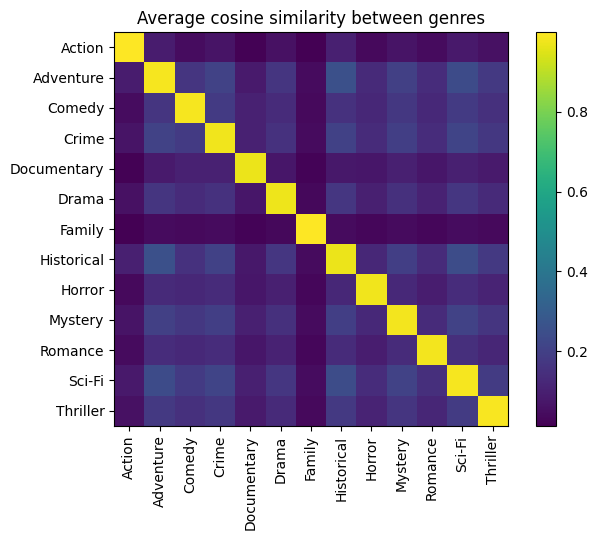

In [17]:
# Visual check: similarity between genres (average cosine)
g = movies.groupby('Genre').indices
names = sorted(g)
avg = pd.DataFrame([[similarity[np.ix_(g[a], g[b])].mean() for b in names] for a in names], index=names, columns=names)
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(avg, cmap='viridis'); ax.set_xticks(range(len(names)), names, rotation=90); ax.set_yticks(range(len(names)), names)
plt.colorbar(im); ax.set_title('Average cosine similarity between genres'); plt.tight_layout(); plt.show()

## 12. Save Model / Data
The Streamlit app loads these files (no retraining needed).

In [18]:
keep = ['MovieID', 'Title', 'Genre', 'Year', 'Duration', 'Director', 'avg_rating', 'n_ratings', 'weighted_rating']
pickle.dump(movies[keep], open('movies.pkl', 'wb'))
pickle.dump(similarity,  open('similarity.pkl', 'wb'))
pickle.dump(ratings[['UserID', 'MovieID', 'Rating']], open('ratings.pkl', 'wb'))
print('Saved movies.pkl, similarity.pkl, ratings.pkl')

Saved movies.pkl, similarity.pkl, ratings.pkl


## 13–15. Streamlit App → Run Locally → Deploy
```bash
pip install -r requirements.txt
streamlit run app.py
```
Deployment steps are in `README.md`.